In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("Unemployment in India.csv")
print(df.shape)
df.head()

(768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [2]:
print(df.columns.tolist())
df.info()

['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [3]:
#Cleaning data
#a.rename the columns
df.columns = df.columns.str.strip()

df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation",
})

print(df.columns.tolist())

['Region', 'Date', 'Frequency', 'Unemployment_Rate', 'Employed', 'Labour_Participation', 'Area']


In [5]:
#b.remove empty rows
print("Missing values:\n", df.isnull().sum())

df = df.dropna(how="all")
print("Shape after removing empty rows:", df.shape)

Missing values:
 Region                  28
Date                    28
Frequency               28
Unemployment_Rate       28
Employed                28
Labour_Participation    28
Area                    28
dtype: int64
Shape after removing empty rows: (740, 7)


In [ ]:
#c.clean the text values
for col in ["Region", "Frequency", "Area", "Date"]:
    df[col] = df[col].str.strip()

print(df["Frequency"].unique())
print(df["Area"].unique())

['Monthly' nan]
['Rural' nan 'Urban']


In [6]:
#d.convert the date column to real datetime
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

print(df["Date"].min(), "to", df["Date"].max())
df.dtypes

2019-05-31 00:00:00 to 2020-06-30 00:00:00


Region                          object
Date                    datetime64[ns]
Frequency                       object
Unemployment_Rate              float64
Employed                       float64
Labour_Participation           float64
Area                            object
Month                            int32
Year                             int32
dtype: object

In [7]:
#e.duplicates and quick summary
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

print("States:", df["Region"].nunique())
df.describe().round(2)

Duplicates: 0
States: 28


,Date,Unemployment_Rate,Employed,Labour_Participation,Month,Year
count,740,740.00,740.00,740.00,740.00,740.00
mean,2019-12-12 18:36:58.378378496,11.79,7204460.03,42.63,6.39,2019.42
min,2019-05-31 00:00:00,0.00,49420.00,13.33,1.00,2019.00
25%,2019-08-31 00:00:00,4.66,1190404.50,38.06,4.00,2019.00
50%,2019-11-30 00:00:00,8.35,4744178.50,41.16,6.00,2019.00
75%,2020-03-31 00:00:00,15.89,11275489.50,45.50,9.00,2020.00
max,2020-06-30 00:00:00,76.74,45777509.00,72.57,12.00,2020.00
std,NaN,10.72,8087988.43,8.11,3.24,0.49


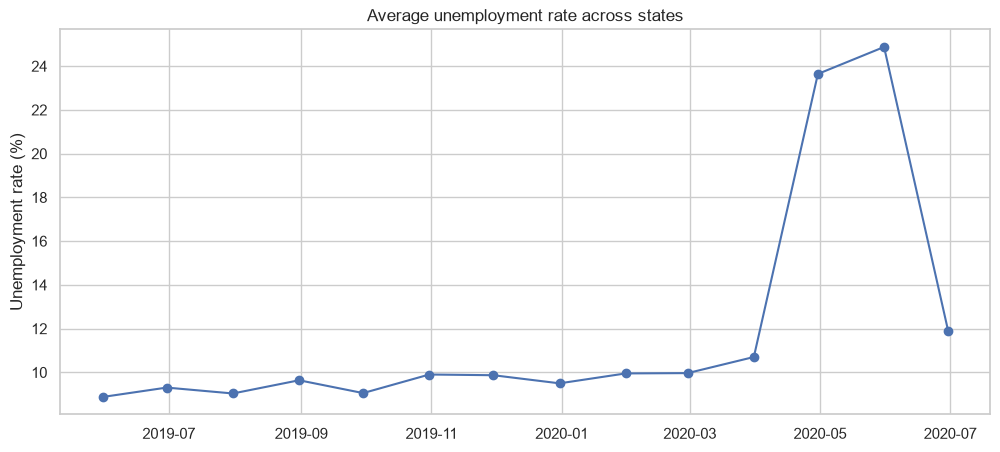

In [8]:
monthly_avg = df.groupby("Date")["Unemployment_Rate"].mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")
plt.title("Average unemployment rate across states")
plt.ylabel("Unemployment rate (%)")
plt.show()

In [10]:
df["Labour_Force"] = df["Employed"] / (1 - df["Unemployment_Rate"] / 100)
df["Unemployed"] = df["Labour_Force"] - df["Employed"]

national = df.groupby("Date")[["Unemployed", "Labour_Force"]].sum()
national["Rate"] = national["Unemployed"] / national["Labour_Force"] * 100
national["Rate"].round(2)

Date
2019-05-31     7.04
2019-06-30     7.88
2019-07-31     7.37
2019-08-31     8.08
2019-09-30     7.08
2019-10-31     8.11
2019-11-30     7.25
2019-12-31     7.73
2020-01-31     7.24
2020-02-29     7.78
2020-03-31     8.67
2020-04-30    24.16
2020-05-31    23.57
2020-06-30    11.04
Name: Rate, dtype: float64

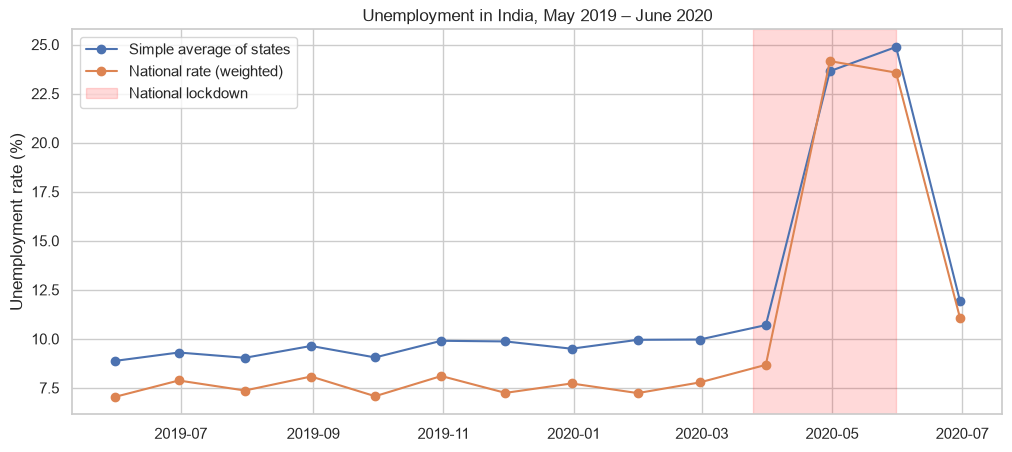

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o", label="Simple average of states")
plt.plot(national.index, national["Rate"], marker="o", label="National rate (weighted)")

plt.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"),
            color="red", alpha=0.15, label="National lockdown")

plt.title("Unemployment in India, May 2019 – June 2020")
plt.ylabel("Unemployment rate (%)")
plt.legend()
plt.show()

In [12]:
#measure the covid impact by state
def period(d):
    if d < pd.Timestamp("2020-03-01"):
        return "1. Before Covid"
    elif d < pd.Timestamp("2020-04-01"):
        return "2. March 2020"
    elif d <= pd.Timestamp("2020-05-31"):
        return "3. Lockdown"
    else:
        return "4. Unlock (June)"

df["Period"] = df["Date"].apply(period)
df["Period"].value_counts().sort_index()

Period
1. Before Covid     536
2. March 2020        52
3. Lockdown         102
4. Unlock (June)     50
Name: count, dtype: int64

In [13]:
#national rate per period
nat_period = df.groupby("Period")[["Unemployed", "Labour_Force"]].sum()
nat_period["Rate"] = (nat_period["Unemployed"] / nat_period["Labour_Force"] * 100).round(2)
nat_period["Rate"]

Period
1. Before Covid      7.55
2. March 2020        8.67
3. Lockdown         23.85
4. Unlock (June)    11.04
Name: Rate, dtype: float64

In [14]:
#rate per state ,per period
state = df.groupby(["Region", "Period"])[["Unemployed", "Labour_Force"]].sum()
state["Rate"] = state["Unemployed"] / state["Labour_Force"] * 100

state_rates = state["Rate"].unstack().round(2)
state_rates.head(10)

Period,1. Before Covid,2. March 2020,3. Lockdown,4. Unlock (June)
Region,,,,
Andhra Pradesh,4.68,5.79,18.93,2.11
Assam,5.09,4.78,9.43,0.60
Bihar,11.46,15.43,46.40,19.52
Chandigarh,16.50,21.43,NaN,7.22
Chhattisgarh,7.26,7.54,7.28,14.45
Delhi,15.16,17.04,32.08,18.19
Goa,9.48,4.76,14.77,NaN
Gujarat,5.12,6.66,16.06,2.82
Haryana,22.66,25.05,39.61,33.56


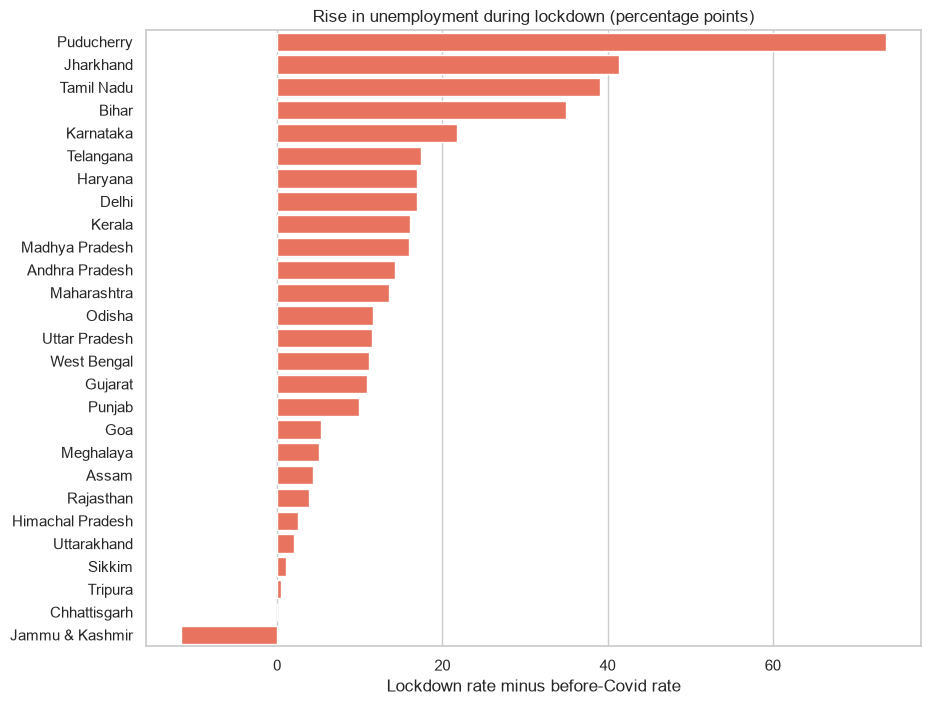

Period,1. Before Covid,3. Lockdown,Increase
Region,,,
Puducherry,1.87,75.56,73.69
Jharkhand,11.82,53.18,41.36
Tamil Nadu,2.83,41.91,39.08
Bihar,11.46,46.40,34.94
Karnataka,3.28,25.07,21.79


In [15]:
#measuring which states were hits the hardest 
state_rates["Increase"] = state_rates["3. Lockdown"] - state_rates["1. Before Covid"]
impact = state_rates.dropna(subset=["Increase"]).sort_values("Increase", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x=impact["Increase"], y=impact.index, color="tomato")
plt.title("Rise in unemployment during lockdown (percentage points)")
plt.xlabel("Lockdown rate minus before-Covid rate")
plt.ylabel("")
plt.show()

impact[["1. Before Covid", "3. Lockdown", "Increase"]].head(5)

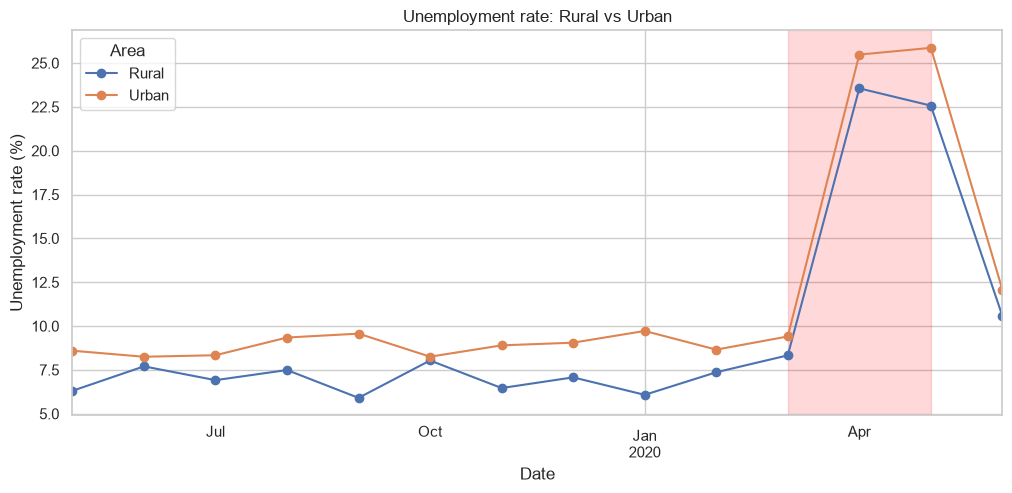

In [16]:
#comparing rural vs urban unemployment over time

area = df.groupby(["Date", "Area"])[["Unemployed", "Labour_Force"]].sum()
area["Rate"] = area["Unemployed"] / area["Labour_Force"] * 100
area_rates = area["Rate"].unstack()

area_rates.plot(figsize=(12, 5), marker="o")
plt.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color="red", alpha=0.15)
plt.title("Unemployment rate: Rural vs Urban")
plt.ylabel("Unemployment rate (%)")
plt.show()

In [17]:
#rural vs urban by period
ap = df.groupby(["Period", "Area"])[["Unemployed", "Labour_Force"]].sum()
ap["Rate"] = (ap["Unemployed"] / ap["Labour_Force"] * 100).round(2)
ap["Rate"].unstack()

Area,Rural,Urban
Period,,
1. Before Covid,6.93,8.87
2. March 2020,8.33,9.41
3. Lockdown,23.04,25.68
4. Unlock (June),10.58,12.07


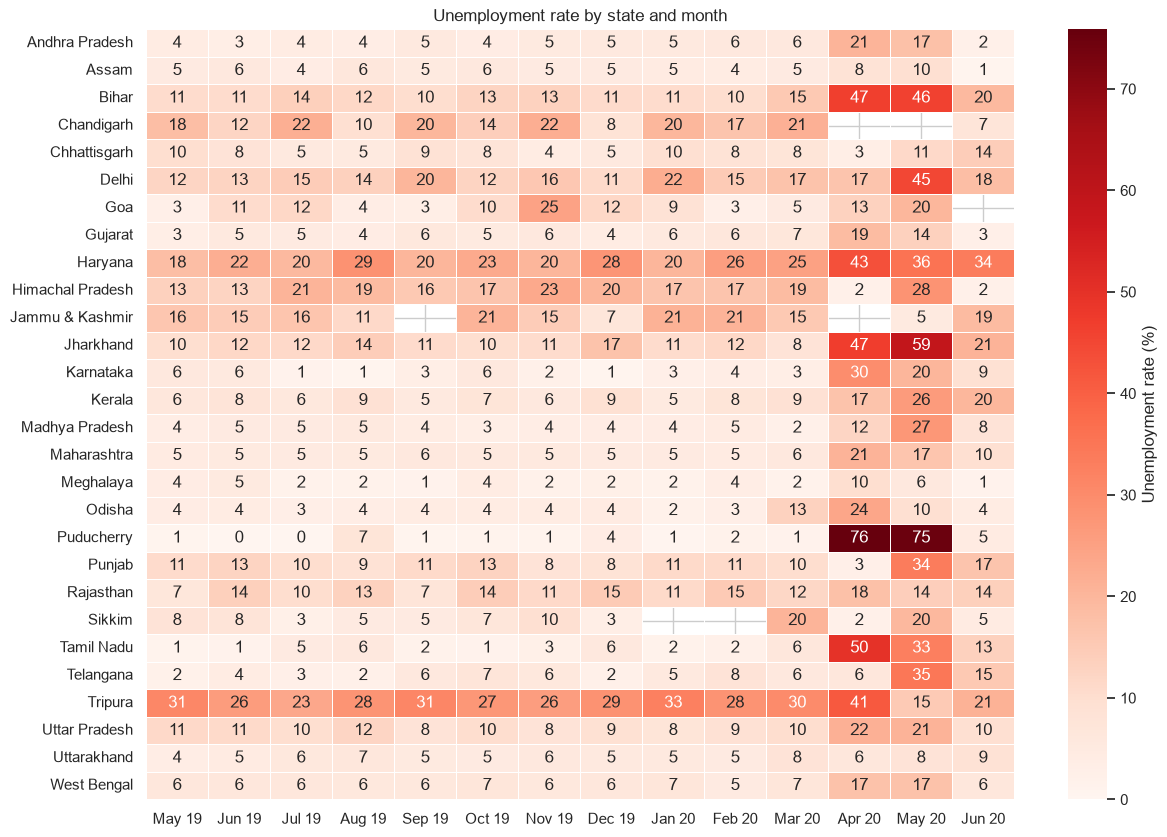

In [18]:
#heatmap: every state ,every month
sm = df.groupby(["Region", "Date"])[["Unemployed", "Labour_Force"]].sum()
sm["Rate"] = sm["Unemployed"] / sm["Labour_Force"] * 100
heat = sm["Rate"].unstack()
heat.columns = heat.columns.strftime("%b %y")

plt.figure(figsize=(14, 10))
sns.heatmap(heat, cmap="Reds", annot=True, fmt=".0f", linewidths=0.5,
            cbar_kws={"label": "Unemployment rate (%)"})
plt.title("Unemployment rate by state and month")
plt.xlabel(""); plt.ylabel("")
plt.show()

In [21]:
def load_and_clean(path):
    data = pd.read_csv(path)
    data.columns = data.columns.str.strip()
    data = data.rename(columns={
        "Estimated Unemployment Rate (%)": "Unemployment_Rate",
        "Estimated Employed": "Employed",
        "Estimated Labour Participation Rate (%)": "Labour_Participation",
        "Region.1": "Zone",
    })
    data = data.dropna(how="all")
    for col in data.select_dtypes(include="object").columns:
        data[col] = data[col].str.strip()
    data["Date"] = pd.to_datetime(data["Date"], dayfirst=True)
    data["Labour_Force"] = data["Employed"] / (1 - data["Unemployment_Rate"] / 100)
    data["Unemployed"] = data["Labour_Force"] - data["Employed"]
    return data

df2 = load_and_clean("Unemployment_Rate_upto_11_2020.csv")
print(df2.shape)
print(df2["Date"].min(), "to", df2["Date"].max())
df2.head()

(267, 11)
2020-01-31 00:00:00 to 2020-10-31 00:00:00


,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation,Zone,longitude,latitude,Labour_Force,Unemployed
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74,1.760002e+07,9.644809e+05
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74,1.756998e+07,1.024330e+06
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74,1.685723e+07,9.760337e+05
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74,1.426206e+07,2.925148e+06
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74,1.573071e+07,2.741862e+06


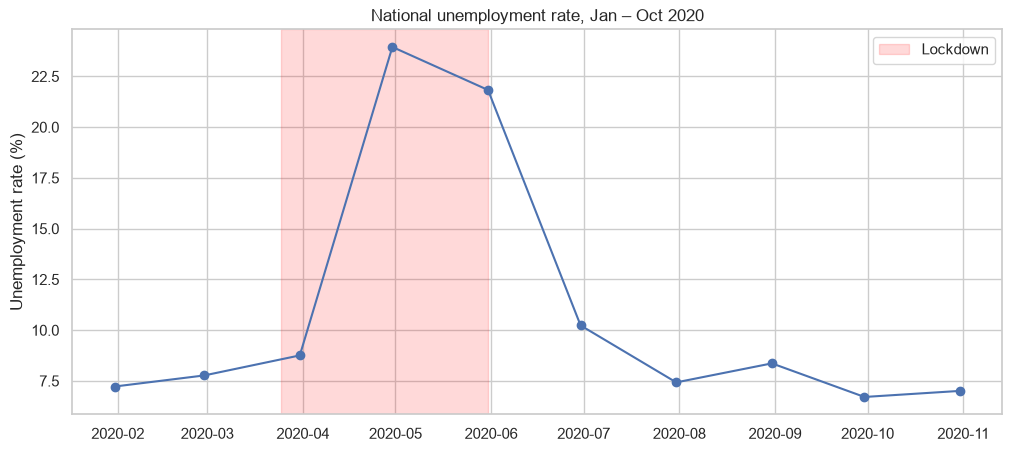

Date
2020-01-31     7.22
2020-02-29     7.77
2020-03-31     8.76
2020-04-30    23.95
2020-05-31    21.83
2020-06-30    10.23
2020-07-31     7.43
2020-08-31     8.36
2020-09-30     6.71
2020-10-31     7.01
Name: Rate, dtype: float64

In [22]:
nat2 = df2.groupby("Date")[["Unemployed", "Labour_Force"]].sum()
nat2["Rate"] = nat2["Unemployed"] / nat2["Labour_Force"] * 100

plt.figure(figsize=(12, 5))
plt.plot(nat2.index, nat2["Rate"], marker="o")
plt.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color="red", alpha=0.15, label="Lockdown")
plt.title("National unemployment rate, Jan – Oct 2020")
plt.ylabel("Unemployment rate (%)")
plt.legend()
plt.show()

nat2["Rate"].round(2)

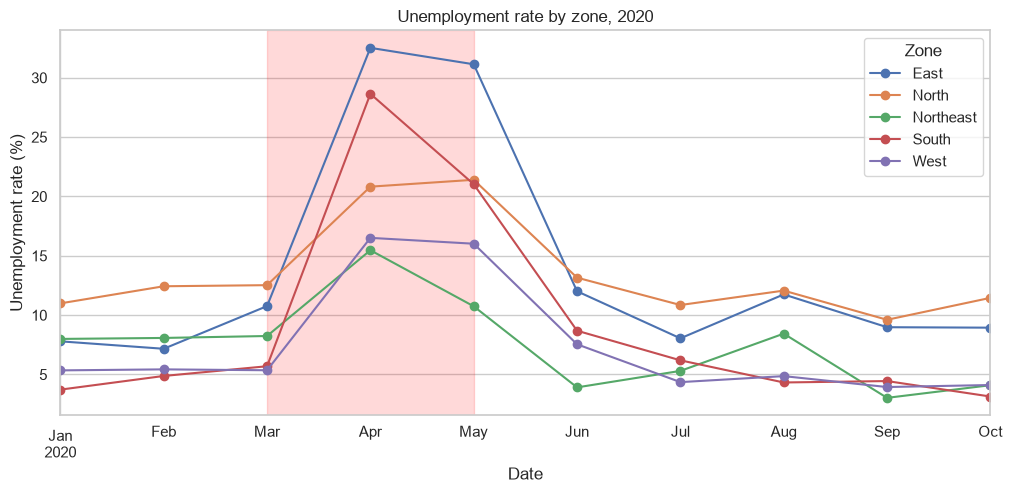

,Feb (before),Apr (peak),Oct (after)
Zone,,,
East,7.17,32.52,8.94
North,12.43,20.82,11.46
Northeast,8.08,15.47,4.10
South,4.87,28.64,3.14
West,5.43,16.51,4.11


In [23]:
#recovey by rate 
zone = df2.groupby(["Date", "Zone"])[["Unemployed", "Labour_Force"]].sum()
zone["Rate"] = zone["Unemployed"] / zone["Labour_Force"] * 100
zone_rates = zone["Rate"].unstack()

zone_rates.plot(figsize=(12, 5), marker="o")
plt.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color="red", alpha=0.15)
plt.title("Unemployment rate by zone, 2020")
plt.ylabel("Unemployment rate (%)")
plt.show()

recovery = zone_rates.loc[["2020-02-29", "2020-04-30", "2020-10-31"]].T.round(2)
recovery.columns = ["Feb (before)", "Apr (peak)", "Oct (after)"]
recovery

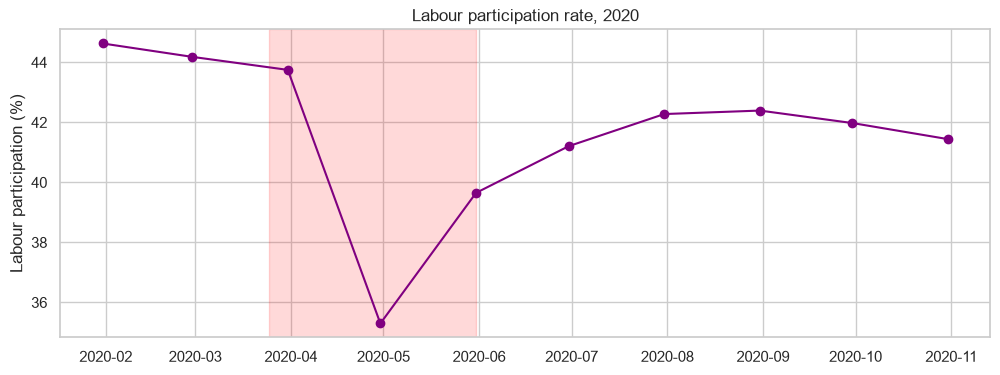

Date
2020-01-31    44.63
2020-02-29    44.18
2020-03-31    43.75
2020-04-30    35.30
2020-05-31    39.65
2020-06-30    41.20
2020-07-31    42.27
2020-08-31    42.39
2020-09-30    41.97
2020-10-31    41.44
Name: Labour_Participation, dtype: float64

In [24]:
#checking the recovery is real or not
lp = df2.groupby("Date")["Labour_Participation"].mean()

plt.figure(figsize=(12, 4))
plt.plot(lp.index, lp.values, marker="o", color="purple")
plt.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color="red", alpha=0.15)
plt.title("Labour participation rate, 2020")
plt.ylabel("Labour participation (%)")
plt.show()

lp.round(2)